# C · Gradient boosting forecast and Apriori error analysis

**Group project 02807, DK1 day-ahead price forecasting, member C - Fu Philip (s260114).**

This notebook covers two parts of the project:

1. **Forecast:** a gradient-boosting model (one model per local clock hour) for next-day hourly DK1 prices,
   compared with the lead's Ridge baseline and with three variants that each change one setting.

2. **Error analysis with Apriori:** Which combinations of season, time of day and K-means cluster
   from Justin( teammember B) are associated with large forecast errors, found on 2023 and re-checked on 2024.

**How to run**

1. Clone the repository and open a terminal in its root folder.
2. Install the pinned packages: `python -m pip install -r requirements-lock.txt` (Python 3.10 or newer).
   The reported numbers come from these versions (scikit-learn 1.7.2); other versions give slightly different results.
3. Open this notebook from `team/c-gradient-boosting/` and run all cells.

Forecast runs that already exist in `results/team/` and cover all of 2023–2024 are loaded, not recomputed. A missing or incomplete run is computed
with the shared benchmark, which takes about 4–7 minutes per gradient-boosting run on two CPU cores
(Ridge takes seconds). Set `FORCE_RERUN = True` to recompute everything (about 25 minutes).
All data comes from the bundled snapshot in `team/data/`; no downloads or API keys are needed.

**Team's Protocol.** Walk-forward evaluation over January 2023 – December 2024, refitting at the
start of each month on all earlier days. Both years are historical development data. Settings and rules are
chosen on 2023 only; 2024 is used as a check.

## 1. Setup

In [ ]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

#Locating the repository root from wherever the notebook was opened.
ROOT = Path.cwd().resolve()
while not (ROOT / "scripts" / "run_team_benchmark.py").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Open this notebook inside the CT4DP repository.")
    ROOT = ROOT.parent
HERE = ROOT / "team" / "c-gradient-boosting"
sys.path.insert(0, str(HERE))

from run_experiments import BASE, VARIANTS #starter settings and one-change variants
from analyze_apriori import analyze, load_hours #shipped Apriori analysis
from summarize import (DEFAULT_RUNS, all_rules, check_runs,  #run list, coverage check,
                       comparison, coverage_problem)    

RESULTS = ROOT / "results" / "team"
REGIMES = ROOT / "team" / "b-random-forest" / "temporaryresults" / "regimes.csv"  # B's K-means labels
FORCE_RERUN = False
pd.set_option("display.width", 160)
print("Repository found:", ROOT.name)

Repository found: CT4DP


## 2. Forecast experiments

The starter model trains one `HistGradientBoostingRegressor` per local clock hour on the shared daily features
(lagged prices for DK1, DK2, DE-LU, NL and SE4, calendar features and archived JMA weather forecasts).
Each variant changes exactly one setting, with one hypothesis each:

| Variant | Change | Hypothesis |
| --- | --- | --- |
| `smaller_leaves` | 15 → 7 leaves per tree | simpler trees overfit less to rare price spikes |
| `strong_l2` | L2 penalty 1 → 10 | shrinking leaf values damps extreme predictions |
| `absolute_loss` | squared → absolute error | optimises the reported MAE directly and is less pulled by spikes |

In [2]:
print("Starter settings:", BASE)
for name, change in VARIANTS.items():
    print(f"{name:15s} {change}")

Starter settings: {'max_iter': 60, 'learning_rate': 0.08, 'max_leaf_nodes': 15, 'max_bins': 63, 'min_samples_leaf': 30, 'l2_regularization': 1.0, 'early_stopping': False, 'random_state': 42}
smaller_leaves  {'max_leaf_nodes': 7}
strong_l2       {'l2_regularization': 10.0}
absolute_loss   {'loss': 'absolute_error'}


`ensure_run` loads a finished full-period run or computes it with the shared benchmark; `check_runs` then confirms that every run covers all 17,544 hours of 2023–2024. The starter is run through the
team's own runner script, the variants through `run_experiments.py`, so the evaluator, inputs, dates and
metrics are identical for every run.

In [ ]:
RUNS = {
    "gradient_boosting_baseline": [sys.executable, "scripts/run_team_benchmark.py", "--model",
                                   "gradient_boosting", "--data", "--output",
                                   "results/team/gradient_boosting_baseline"],
    **{f"gradient_boosting_{v}": [sys.executable, "team/c-gradient-boosting/run_experiments.py", v]
       for v in VARIANTS},
    "ridge": [sys.executable, "scripts/run_team_benchmark.py", "--model", "ridge", "--data"],
}
assert list(RUNS) == DEFAULT_RUNS

def ensure_run(name):
    folder = RESULTS / name
    if FORCE_RERUN or coverage_problem(folder):
        print(f"Running {name} ...")
        subprocess.run(RUNS[name], cwd=ROOT, check=True)

for name in RUNS:
    ensure_run(name)
found = check_runs(DEFAULT_RUNS)   #stops execution with a message if any run does not cover specified period 2023–2024
print("Available runs:", ", ".join(found))

Available runs: gradient_boosting_baseline, gradient_boosting_smaller_leaves, gradient_boosting_strong_l2, gradient_boosting_absolute_loss, ridge


### 2.1 Accuracy and runtime

MAE and RMSE use all hours. The hit rate counts forecasts within ±5% of the actual price, only for hours with
an absolute price of at least 20 EUR/MWh (`eligible`). `fit_seconds` is the summed monthly fit time per year,
excluding data loading.

In [4]:
table = comparison(found)
cols = ["run", "year", "hours", "mae", "rmse", "hits_5pct", "eligible", "rate_5pct",
        "negative_hours", "negative_mae", "fit_seconds"]
table[cols].round(3).sort_values(["year", "mae"])

,run,year,hours,mae,rmse,hits_5pct,eligible,rate_5pct,negative_hours,negative_mae,fit_seconds
0,gradient_boosting_baseline,2023,8760,18.389,26.867,1770,7738,0.229,281,35.302,206.306
4,gradient_boosting_strong_l2,2023,8760,18.660,27.238,1734,7738,0.224,281,36.866,204.819
8,ridge,2023,8760,18.780,26.654,1575,7738,0.204,281,31.563,1.181
2,gradient_boosting_smaller_leaves,2023,8760,18.949,27.431,1680,7738,0.217,281,38.904,158.965
6,gradient_boosting_absolute_loss,2023,8760,19.109,27.861,1692,7738,0.219,281,39.425,225.733
1,gradient_boosting_baseline,2024,8784,16.580,27.467,1455,7620,0.191,375,20.690,207.996
5,gradient_boosting_strong_l2,2024,8784,16.652,27.599,1425,7620,0.187,375,21.170,210.085
7,gradient_boosting_absolute_loss,2024,8784,17.319,28.967,1577,7620,0.207,375,26.203,237.510
3,gradient_boosting_smaller_leaves,2024,8784,17.719,28.810,1342,7620,0.176,375,25.274,158.906
9,ridge,2024,8784,18.339,29.521,1356,7620,0.178,375,19.430,1.206


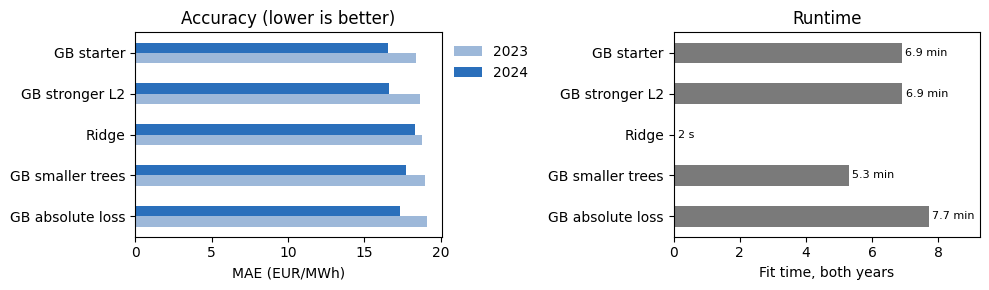

In [5]:
short = {"ridge": "Ridge", "gradient_boosting_baseline": "GB starter", "gradient_boosting_strong_l2": "GB stronger L2",
         "gradient_boosting_smaller_leaves": "GB smaller trees", "gradient_boosting_absolute_loss": "GB absolute loss"}
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
pivot = table.pivot(index="run", columns="year", values="mae").sort_values(2023, ascending=False).rename(index=short)
pivot.plot.barh(ax=ax[0], color=["#9db8d9", "#2a6fbb"])
ax[0].set_xlabel("MAE (EUR/MWh)"); ax[0].set_ylabel(""); ax[0].set_title("Accuracy (lower is better)")
ax[0].legend(title=None, frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
fit = table.groupby("run")["fit_seconds"].sum().rename(index=short).reindex(pivot.index) / 60
fit.plot.barh(ax=ax[1], color="#7a7a7a")
for i, v in enumerate(fit):
    ax[1].text(v + 0.1, i, f"{v * 60:.0f} s" if v < 1 else f"{v:.1f} min", va="center", fontsize=8)
ax[1].set_xlim(0, fit.max() * 1.2)
ax[1].set_xlabel("Fit time, both years"); ax[1].set_ylabel(""); ax[1].set_title("Runtime")
plt.tight_layout(); plt.show()

**Decision (made on 2023):** keep the starter settings. None of the three changes improved 2023 MAE or the 2023
hit rate. Gradient boosting beats Ridge on MAE in both years and on the hit rate, but it is worse in negative-price
hours and needs far more fit time. Absolute-error loss had the best 2024 hit rate, but it was worse in 2023, and
picking it would mean using 2024 to choose.

## 3. Apriori: when do the forecasts miss?

Each forecast hour becomes a basket of items: `season`, `time_of_day` (four 6-hour blocks) and, when supplied,
the day's K-means `cluster` from member B. An hour is a **large error** if its absolute error is above the
2023 90th percentile of that model's errors. The project's own Apriori implementation
(`src/energy_pilot/mining.py`, vertical counting, no library) finds itemsets with at least 5% support in 2023.
Rules need at least 20 large errors in 2023. Each rule is then scored unchanged on 2024, where lift is measured
against the 2024 large-error rate.

### 3.1 Shipped analysis: strongest rule per group

The shipped script picks the rule with the highest 2023 lift in each group (calendar only, and containing a cluster).

In [6]:
gb_hours = load_hours(found["gradient_boosting_baseline"] / "predictions.csv.gz", REGIMES)
strongest = analyze(gb_hours)
show = ["group", "antecedent", "threshold_eur_mwh", "development_support", "development_confidence",
        "development_lift", "evaluation_support", "evaluation_confidence", "evaluation_lift"]
strongest[show].round(3).T

,0,1
group,calendar,cluster
antecedent,season=spring & time_of_day=afternoon,cluster=1 & time_of_day=afternoon
threshold_eur_mwh,41.256,41.256
development_support,0.063,0.055
development_confidence,0.207,0.167
development_lift,2.065,1.667
evaluation_support,0.063,0.041
evaluation_confidence,0.047,0.061
evaluation_lift,0.751,0.974


Both selected rules fail in 2024 (lift below 1 means no more large errors than usual).
Ranking by 2023 lift alone picks unstable patterns, so the next step looks at every rule.

### 3.2 All rules, 2023 vs 2024, for gradient boosting and Ridge

In [7]:
rules = {name: all_rules(load_hours(found[name] / "predictions.csv.gz", REGIMES))
         for name in ["gradient_boosting_baseline", "ridge"]}
for name, r in rules.items():
    held = (r.lift_2023 > 1.2) & (r.lift_2024 > 1)
    print(f"{name}: {len(r)} rules, threshold {r.attrs['threshold']:.2f} EUR/MWh, "
          f"{(r.lift_2023 > 1.2).sum()} with 2023 lift > 1.2, {held.sum()} of those still > 1 in 2024")
rules["gradient_boosting_baseline"].head(10).round(3)

gradient_boosting_baseline: 46 rules, threshold 41.26 EUR/MWh, 13 with 2023 lift > 1.2, 9 of those still > 1 in 2024
ridge: 44 rules, threshold 40.54 EUR/MWh, 16 with 2023 lift > 1.2, 12 of those still > 1 in 2024


,antecedent,group,support_2023,confidence_2023,lift_2023,large_errors_2023,support_2024,confidence_2024,lift_2024,large_errors_2024
36,season=spring & time_of_day=afternoon,calendar,0.063,0.207,2.065,114,0.063,0.047,0.751,26
17,season=autumn & time_of_day=evening,calendar,0.062,0.201,2.015,110,0.062,0.137,2.190,75
23,cluster=1 & time_of_day=afternoon,cluster,0.055,0.167,1.667,80,0.041,0.061,0.974,22
32,season=winter & time_of_day=afternoon,calendar,0.062,0.159,1.593,86,0.062,0.092,1.460,50
35,season=autumn & time_of_day=morning,calendar,0.062,0.152,1.520,83,0.062,0.081,1.285,44
16,cluster=2 & season=autumn,cluster,0.110,0.147,1.469,141,0.109,0.083,1.327,80
42,cluster=0 & time_of_day=afternoon,cluster,0.088,0.143,1.434,111,0.089,0.057,0.913,45
4,time_of_day=afternoon,calendar,0.250,0.142,1.420,311,0.250,0.084,1.343,185
11,cluster=0 & time_of_day=evening,cluster,0.088,0.130,1.305,101,0.089,0.076,1.217,60
31,cluster=2 & time_of_day=afternoon,cluster,0.099,0.128,1.276,111,0.107,0.089,1.422,84


In [8]:
key = ["season=autumn & time_of_day=evening", "season=autumn & time_of_day=morning",
       "season=spring & time_of_day=afternoon", "cluster=1 & time_of_day=afternoon",
       "cluster=0 & time_of_day=afternoon", "cluster=0 & time_of_day=evening"]
both = pd.concat({name: r.set_index("antecedent").loc[key, ["support_2023", "lift_2023", "lift_2024"]]
                  for name, r in rules.items()}, axis=1)
both.round(2)

gradient_boosting_baseline                            ridge                    
                                                    support_2023 lift_2023 lift_2024 support_2023 lift_2023 lift_2024
antecedent                                                                                                           
season=autumn & time_of_day=evening                         0.06      2.01      2.19         0.06      2.18      1.88
season=autumn & time_of_day=morning                         0.06      1.52      1.28         0.06      1.70      1.57
season=spring & time_of_day=afternoon                       0.06      2.07      0.75         0.06      1.99      0.63
cluster=1 & time_of_day=afternoon                           0.05      1.67      0.97         0.05      0.83      0.96
cluster=0 & time_of_day=afternoon                           0.09      1.43      0.91         0.09      1.61      1.02
cluster=0 & time_of_day=evening                             0.09      1.30      1.22         0.09      1.59      1.33

### 3.3 Error rate per cluster

Cluster 3 (the day after a very expensive day) covers fewer than 5% of hours, so no itemset containing it
reaches the minimum support and Apriori cannot report it. This cell checks every cluster directly. It is an
inspection after the rule search, not part of the pre-set analysis.

In [9]:
rows = []
for name in ["gradient_boosting_baseline", "ridge"]:
    h = load_hours(found[name] / "predictions.csv.gz", REGIMES)
    threshold = h.loc[h.year == 2023, "absolute_error"].quantile(0.90)
    h["large"] = h.absolute_error > threshold
    per = h.groupby(["cluster", "year"]).agg(days=("day", "nunique"), large_rate=("large", "mean"),
                                             mae=("absolute_error", "mean"))
    per["lift"] = per.large_rate / h.groupby("year").large.mean().reindex(per.index.get_level_values("year")).values
    rows.append(per.assign(model=name))
cluster_table = pd.concat(rows).reset_index().set_index(["model", "cluster", "year"])
cluster_table.round(3).unstack("year")

days      large_rate            mae           lift       
year                               2023 2024       2023   2024    2023    2024   2023   2024
model                      cluster                                                          
gradient_boosting_baseline 0        129  131      0.105  0.045  19.023  14.797  1.053  0.710
                           1         80   60      0.093  0.051  17.402  14.847  0.928  0.808
                           2        145  157      0.094  0.071  18.003  16.917  0.937  1.138
                           3         11   18      0.174  0.160  23.223  32.403  1.742  2.546
ridge                      0        129  131      0.121  0.080  20.086  16.839  1.208  0.891
                           1         80   60      0.050  0.060  15.790  14.804  0.495  0.674
                           2        145  157      0.103  0.089  18.768  18.548  1.029  0.998
                           3         11   18      0.186  0.259  25.366  39.216  1.856  2.894

### 3.4 Figure used in the report

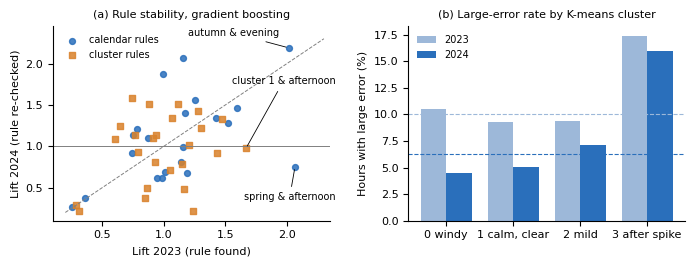

In [10]:
g = rules["gradient_boosting_baseline"]
plt.rcParams.update({"font.size": 8, "axes.spines.top": False, "axes.spines.right": False})
fig, ax = plt.subplots(1, 2, figsize=(7, 2.7))
for group, colour, marker in [("calendar", "#2a6fbb", "o"), ("cluster", "#d9822b", "s")]:
    s = g[g.group == group]
    ax[0].scatter(s.lift_2023, s.lift_2024, c=colour, marker=marker, s=18, label=f"{group} rules", alpha=.85)
ax[0].plot([0.2, 2.3], [0.2, 2.3], color="grey", lw=.7, ls="--"); ax[0].axhline(1, color="grey", lw=.7)
labels = {"season=autumn & time_of_day=evening": ("autumn & evening", (1.2, 2.33)),
          "season=spring & time_of_day=afternoon": ("spring & afternoon", (1.65, 0.35)),
          "cluster=1 & time_of_day=afternoon": ("cluster 1 & afternoon", (1.55, 1.75))}
for rule, (text, pos) in labels.items():
    r = g[g.antecedent == rule].iloc[0]
    ax[0].annotate(text, (r.lift_2023, r.lift_2024), xytext=pos, fontsize=7,
                   arrowprops=dict(arrowstyle="-", color="black", lw=.6))
ax[0].set_xlim(0.1, 2.35); ax[0].set_ylim(0.1, 2.45)
ax[0].set_xlabel("Lift 2023 (rule found)"); ax[0].set_ylabel("Lift 2024 (rule re-checked)")
ax[0].legend(frameon=False, loc="upper left", fontsize=7)
ax[0].set_title("(a) Rule stability, gradient boosting", fontsize=8)

gb = cluster_table.loc["gradient_boosting_baseline"]["large_rate"].unstack("year") * 100
base = gb_hours.assign(large=gb_hours.absolute_error > strongest.threshold_eur_mwh.iloc[0]).groupby("year").large.mean() * 100
x, w = np.arange(4), .38
ax[1].bar(x - w/2, gb[2023], w, color="#9db8d9", label="2023")
ax[1].bar(x + w/2, gb[2024], w, color="#2a6fbb", label="2024")
for year, colour in [(2023, "#9db8d9"), (2024, "#2a6fbb")]:
    ax[1].axhline(base[year], color=colour, lw=.8, ls="--")
ax[1].set_xticks(x); ax[1].set_xticklabels(["0 windy", "1 calm, clear", "2 mild", "3 after spike"])
ax[1].set_ylabel("Hours with large error (%)"); ax[1].legend(frameon=False, fontsize=7, loc="upper left")
ax[1].set_title("(b) Large-error rate by K-means cluster", fontsize=8)
plt.tight_layout()
fig.savefig(HERE / "fig_gb_apriori.pdf")
plt.show()

## 4. Findings

- **Forecast:** the gradient-boosting starter is the best of the four settings on 2023 and beats Ridge on MAE in
  both years, at a much higher fit time and with worse errors in negative-price hours.

- **Stable failure pattern:** autumn evenings (and, less strongly, autumn mornings) have about twice the normal
  rate of large errors in both years and for both model families.

- **Unstable rules:** the strongest 2023 rule (spring afternoons) and the strongest cluster rule (cluster 1 &
  afternoon) both fail in 2024. Lift should be read together with stability across years.

- **Clusters:** most cluster rules do not hold in 2024, including each model's strongest one. One cluster rule,
  cluster 0 (windy days) & evening, keeps a lift above 1.2 for both models in both years, but at a lower lift than
  autumn evenings. The one cluster with a clearly higher error rate in both years (cluster 3, the day after a very
  expensive day) is too rare to pass the 5% support threshold, which is a real limitation of support-based mining
  for error analysis.

**Caveats.** This is an exploratory historical analysis: many rules were tested, neighbouring hours are dependent,
both years were inspected in earlier project work, and the cluster 3 result rests on 29 days.